In [1]:
import json
from collections import defaultdict

# JSON 파일 읽기
def read_json_file(file_path):
    with open(file_path, 'r', encoding='utf-8') as file:
        data = [json.loads(line) for line in file]
    return data


def time_to_minutes(time_str):
    parts = time_str.split(':')
    if len(parts) == 3:  # 형식이 "1:11:03"와 같은 경우
        hours, minutes, _ = map(int, parts)
        return hours * 60 + minutes
    elif len(parts) == 2:  # 형식이 "11:03"와 같은 경우
        minutes, _ = map(int, parts)
        return minutes
    else:
        return None  # 알 수 없는 형식

def count_messages_per_minute(messages):
    message_counts = defaultdict(int)
    for message in messages:
        time = message['time']
        minutes = time_to_minutes(time)
        if minutes is not None and minutes >= 0:  # 0초 이상인 경우만 처리
            message_counts[minutes] += 1
    return message_counts


In [2]:
video_id = "JkPUS0Zdwd8"

In [3]:
file_path = f"./youtube_livechat_replay_crawler/chatlog_replay_{video_id}.json"  # JSON 파일 경로를 지정해주세요

chat_data = read_json_file(file_path)

message_counts = count_messages_per_minute(chat_data)

for minute, count in sorted(message_counts.items()):
    print(f"{minute}: {count} messages")


0: 50 messages
1: 62 messages
2: 47 messages
3: 63 messages
4: 61 messages
5: 44 messages
6: 45 messages
7: 39 messages
8: 35 messages
9: 43 messages
10: 42 messages
11: 43 messages
12: 24 messages
13: 36 messages
14: 37 messages
15: 47 messages
16: 35 messages
17: 28 messages
18: 35 messages
19: 45 messages
20: 45 messages
21: 46 messages
22: 47 messages
23: 54 messages
24: 43 messages
25: 34 messages
26: 44 messages
27: 63 messages
28: 51 messages
29: 36 messages
30: 49 messages
31: 44 messages
32: 27 messages
33: 39 messages
34: 55 messages
35: 48 messages
36: 42 messages
37: 49 messages
38: 39 messages
39: 40 messages
40: 46 messages
41: 70 messages
42: 36 messages
43: 36 messages
44: 45 messages
45: 44 messages
46: 35 messages
47: 71 messages
48: 57 messages
49: 60 messages
50: 38 messages
51: 50 messages
52: 50 messages
53: 43 messages
54: 40 messages
55: 48 messages
56: 40 messages
57: 41 messages
58: 44 messages
59: 42 messages
60: 52 messages
61: 34 messages
62: 44 messages
63

In [4]:
message_counts

defaultdict(int,
            {0: 50,
             1: 62,
             2: 47,
             3: 63,
             4: 61,
             5: 44,
             6: 45,
             7: 39,
             8: 35,
             9: 43,
             10: 42,
             11: 43,
             12: 24,
             13: 36,
             14: 37,
             15: 47,
             16: 35,
             17: 28,
             18: 35,
             19: 45,
             20: 45,
             21: 46,
             22: 47,
             23: 54,
             24: 43,
             25: 34,
             26: 44,
             27: 63,
             28: 51,
             29: 36,
             30: 49,
             31: 44,
             32: 27,
             33: 39,
             34: 55,
             35: 48,
             36: 42,
             37: 49,
             38: 39,
             39: 40,
             40: 46,
             41: 70,
             42: 36,
             43: 36,
             44: 45,
             45: 44,
             46: 35,
      

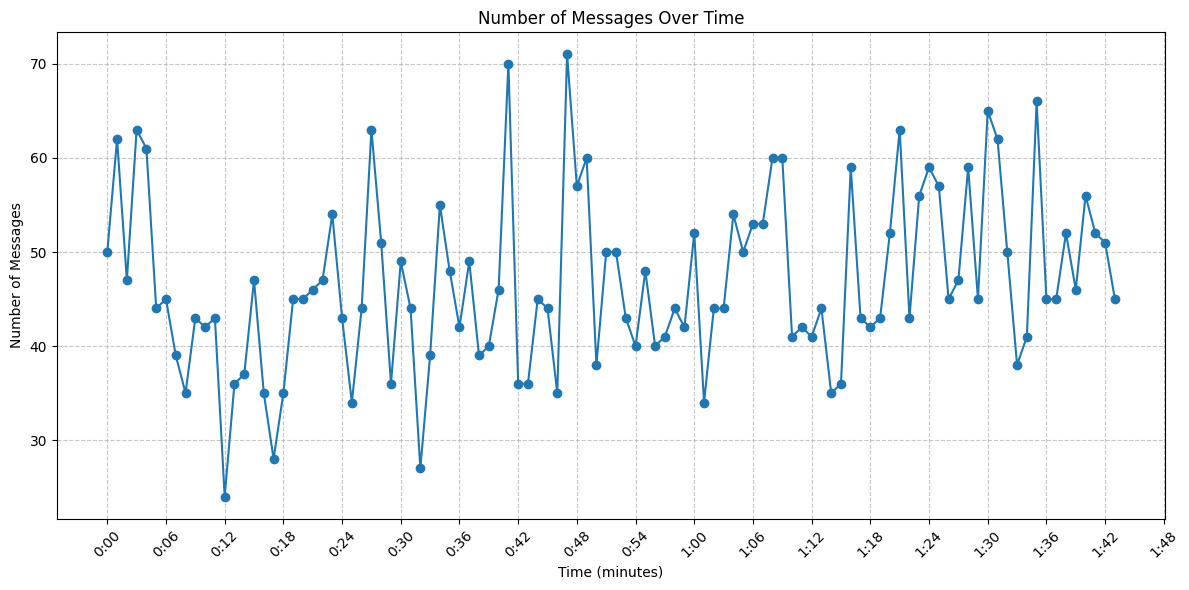

In [5]:
import matplotlib.pyplot as plt

minutes = sorted(message_counts.keys())
counts = [message_counts[m] for m in minutes]

plt.figure(figsize=(12, 6))
plt.plot(minutes, counts, marker='o')
plt.title('Number of Messages Over Time')
plt.xlabel('Time (minutes)')
plt.ylabel('Number of Messages')

# X축 레이블 조정
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(20))  # X축 틱 개수 조정

# X축 레이블을 시:분 형식으로 변경
def format_time(x, pos):
    hours, mins = divmod(int(x), 60)
    return f'{hours}:{mins:02d}'

plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(format_time))

plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('message_count_graph.png')
plt.show()

/tmp/ipykernel_11984/1468665002.py:24: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_11984/1468665002.py:24: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_11984/1468665002.py:24: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_11984/1468665002.py:24: UserWarning: Glyph 52292 (\N{HANGUL SYLLABLE CAE}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_11984/1468665002.py:24: UserWarning: Glyph 54021 (\N{HANGUL SYLLABLE TING}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_11984/1468665002.py:24: UserWarning: Glyph 44079 (\N{HANGUL SYLLABLE GAES}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_11984/1468665002.py:24: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_11984/1468665002.py

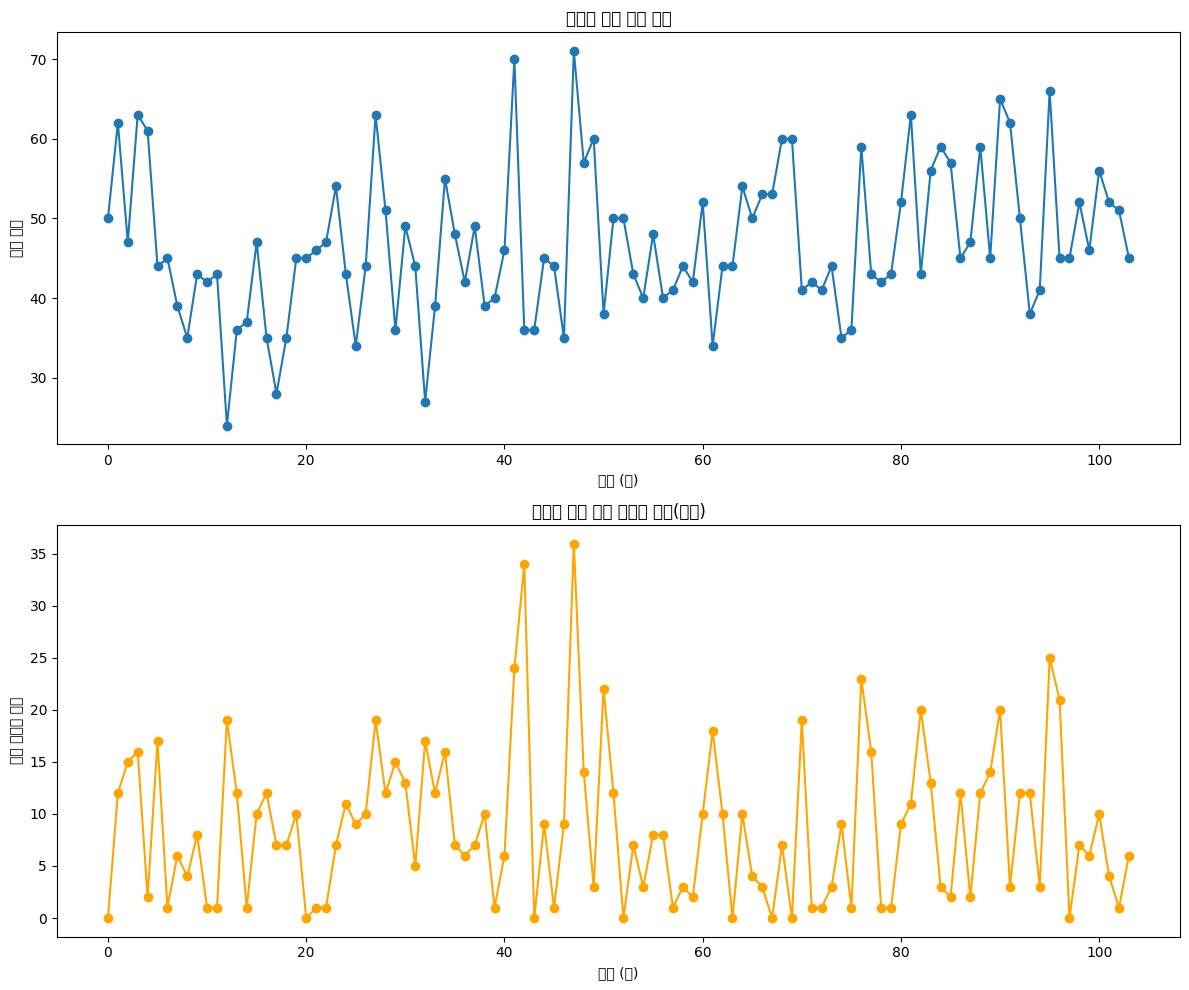

In [6]:
# 데이터 추출
time = list(message_counts.keys())
chat_counts = list(message_counts.values())

# 채팅 갯수의 변화(속도) 계산
chat_speed = [abs(chat_counts[i] - chat_counts[i - 1]) for i in range(1, len(chat_counts))]
chat_speed.insert(0, 0)  # 첫 번째 값은 0으로

# 그래프 생성
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# 첫 번째 그래프: 시간에 따른 채팅 갯수
ax1.plot(time, chat_counts, marker='o')
ax1.set_title('시간에 따른 채팅 갯수')
ax1.set_xlabel('시간 (분)')
ax1.set_ylabel('채팅 갯수')

# 두 번째 그래프: 시간에 따른 채팅 갯수의 변화(속도)
ax2.plot(time, chat_speed, marker='o', color='orange')
ax2.set_title('시간에 따른 채팅 갯수의 변화(속도)')
ax2.set_xlabel('시간 (분)')
ax2.set_ylabel('채팅 갯수의 변화')

plt.tight_layout()
plt.show()

# MRD

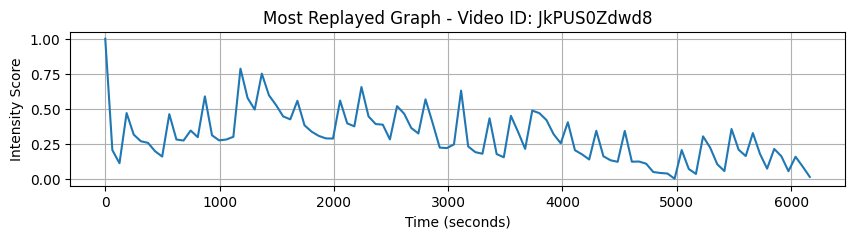

In [7]:

# 동영상 ID

event_lst = [13, 15, 21, 43, 45, 52, 62, 68, 73, 97]
start = 40
end = 97
json_path = f'/source/ms/highlight/json/{video_id}.json'
with open(json_path, 'r') as json_file:
    data = json.load(json_file)


markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(10, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


# 유사도 비교


In [8]:
import numpy as np

In [9]:
 len(intensity_scores)

100

In [10]:
def normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

In [11]:
normalize_data = normalize(chat_speed)

Pearson 상관계수: -0.05771818080374481
P-value: 0.5684057223984961


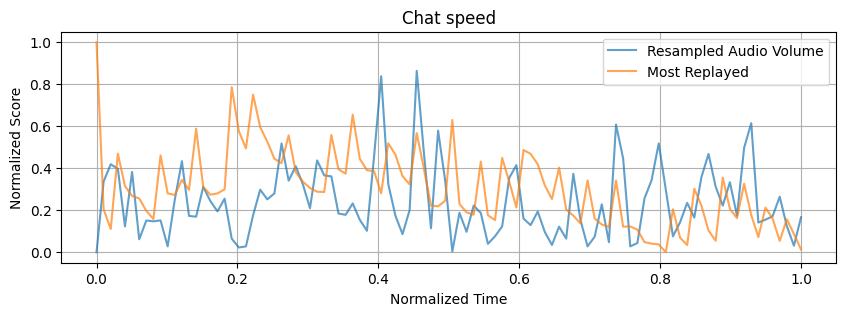

In [12]:
import numpy as np
from scipy import interpolate, stats
import matplotlib.pyplot as plt

# 리샘플링 함수
def resample(x, y, num_points):
    f = interpolate.interp1d(x, y, kind='linear', fill_value='extrapolate')
    x_new = np.linspace(x.min(), x.max(), num_points)
    y_new = f(x_new)
    return x_new, y_new

# 원본 데이터의 x 축 (시간) 생성
x_chat_speed = np.linspace(0, 1, len(minutes))
x_scores = np.linspace(0, 1, len(intensity_scores))

# normalize_ma_rms_cropped를 normalize_scores_cropped의 길이에 맞춰 리샘플링
x_resampled, y_resampled = resample(x_chat_speed, normalize_data, len(intensity_scores))

# Pearson 상관계수 계산
correlation, p_value = stats.pearsonr(y_resampled, intensity_scores)

print(f"Pearson 상관계수: {correlation}")
print(f"P-value: {p_value}")

# 시각화
plt.figure(figsize=(10, 3))
plt.plot(x_resampled, y_resampled, label='Resampled Audio Volume', alpha=0.7)
plt.plot(x_scores, intensity_scores, label='Most Replayed', alpha=0.7)
plt.title('Chat speed')
plt.xlabel('Normalized Time')
plt.ylabel('Normalized Score')
plt.legend()
plt.grid(True)
plt.show()



In [13]:
from sklearn.metrics.pairwise import cosine_similarity

cos_sim = cosine_similarity(y_resampled.reshape(1, -1), np.array(intensity_scores).reshape(1, -1))[0][0]
print(f"Cosine Similarity: {cos_sim}")

Cosine Similarity: 0.6818108839973267
